In [1]:
import pandas as pd
for f in ["llm_gpt_oss_120b_v1", "llm_gpt_oss_20b_v1", "llm_qwen_27b_v1"]:
    df = pd.read_csv(f"../results/{f}.csv")
    print(f"{f}: rows = {len(df)}, empty_predictions (NaN) = {df['pred_intent'].isna().sum()}")

llm_gpt_oss_120b_v1: rows = 385, empty_predictions (NaN) = 32
llm_gpt_oss_20b_v1: rows = 385, empty_predictions (NaN) = 52
llm_qwen_27b_v1: rows = 385, empty_predictions (NaN) = 0


In [2]:
df = pd.read_csv("../results/llm_gpt_oss_120b_v1.csv")

errors = df[df["pred_intent"].isna()]

print(errors["raw"].head(3).values)

<StringArray>
[                                                                  '{"intent":',
 '{"intent": "pending_cash_withdrawal", "sentiment": "negative", "confidence":',
                                                                            nan]
Length: 3, dtype: str


In [3]:
from sklearn.metrics import f1_score, accuracy_score
from pathlib import Path

ROOT = Path.cwd().parent

models = {
    "Baseline (LogReg)": "results/logreg_sample_predictions.csv",
    "GPT-OSS 120B": "results/llm_gpt_oss_120b_v1.csv",
    "GPT-OSS 20B": "results/llm_gpt_oss_20b_v1.csv",
    "Qwen 27B": "results/llm_qwen_27b_v1.csv"
}

results = []
dfs = {}

print("=== Results of Comparison ===")
for name, path in models.items():
    df = pd.read_csv(ROOT / path)

    parse_errors = df["pred_intent"].isna().sum()

    df["pred_intent"] = df["pred_intent"].fillna("PARSE_ERROR")
    dfs[name] = df

    y_true = df["label_text"]
    y_pred = df["pred_intent"]
    
    results.append({
        "Model": name,
        "Macro-F1": round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "Accuracy": round(accuracy_score(y_true, y_pred), 4),
        "Parse Errors": f"{parse_errors} ({parse_errors/len(df)*100:.1f}%)"
    })

df_results = pd.DataFrame(results).sort_values("Macro-F1", ascending=False)
display(df_results)

=== Results of Comparison ===


,Model,Macro-F1,Accuracy,Parse Errors
0,Baseline (LogReg),0.9216,0.9221,0 (0.0%)
1,GPT-OSS 120B,0.8132,0.8130,32 (8.3%)
2,GPT-OSS 20B,0.7562,0.7506,52 (13.5%)
3,Qwen 27B,0.7517,0.7740,0 (0.0%)


In [4]:
v2_120b = pd.read_csv(ROOT / "results/llm_gpt_oss_120b_v2_77.csv")
texts_77 = set(v2_120b["text"].dropna())

v1_120b = dfs["GPT-OSS 120B"] 
v1_120b_sub = v1_120b[v1_120b["text"].isin(texts_77)].copy()

base_df = dfs["Baseline (LogReg)"]
base_sub = base_df[base_df["text"].isin(texts_77)].copy()

def get_metrics(df, name):
    df["pred_intent"] = df["pred_intent"].fillna("PARSE_ERROR")
    return {
        "Model": name,
        "Sample": f"n={len(df)}",
        "Macro-F1": round(f1_score(df["label_text"], df["pred_intent"], average="macro", zero_division=0), 4),
        "Accuracy": round(accuracy_score(df["label_text"], df["pred_intent"]), 4)
    }


ablation_results = [
    get_metrics(base_sub, "Baseline (LogReg)"),
    get_metrics(v1_120b_sub, "GPT-OSS 120B (v1 Zero-shot)"),
    get_metrics(v2_120b, "GPT-OSS 120B (v2 Few-shot)")
]


df_ablation = pd.DataFrame(ablation_results)
print("=== Promts comparison (n=77) ===")
display(df_ablation)

=== Promts comparison (n=77) ===


,Model,Sample,Macro-F1,Accuracy
0,Baseline (LogReg),n=77,0.8680,0.8961
1,GPT-OSS 120B (v1 Zero-shot),n=77,0.7650,0.8052
2,GPT-OSS 120B (v2 Few-shot),n=77,0.7479,0.7792


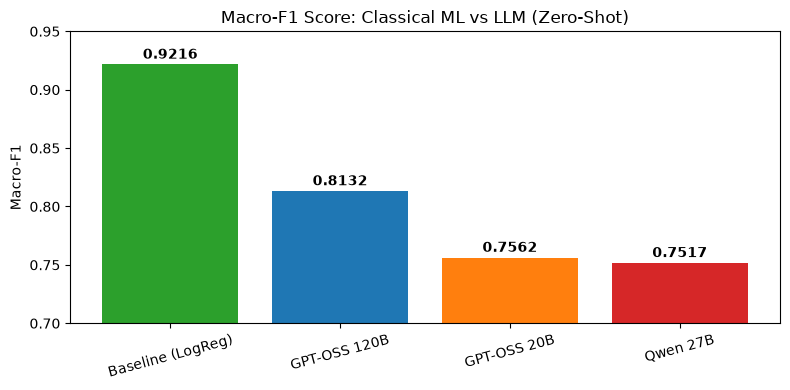

Index(['text', 'label', 'label_text', 'len_words', 'len_chars', 'pred_intent',
       'pred_sentiment', 'confidence', 'raw'],
      dtype='str')


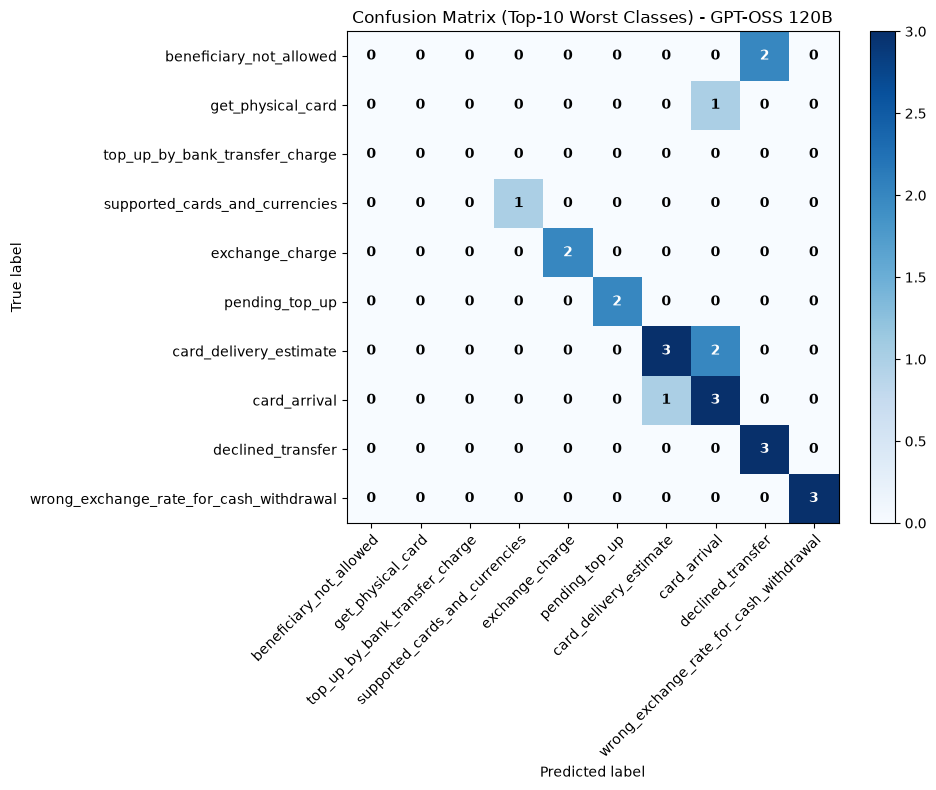

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
ROOT = Path.cwd().parent
plt.figure(figsize=(8, 4))

colors = ['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728']
plt.bar(df_results["Model"], df_results["Macro-F1"], color=colors)

plt.title("Macro-F1 Score: Classical ML vs LLM (Zero-Shot)")
plt.ylim(0.7, 0.95)
plt.ylabel("Macro-F1")

for i, v in enumerate(df_results["Macro-F1"]):
    plt.text(i, v + 0.005, str(v), ha='center', fontweight='bold')

plt.xticks(rotation=15) 
plt.tight_layout()
plt.savefig(ROOT / "results/f1_comparison.png", dpi=150)
plt.show()


best_df = dfs["GPT-OSS 120B"]
print(best_df.columns)
worst_classes = (
    best_df[best_df["pred_intent"] != "PARSE_ERROR"]
    .groupby("label_text")
    .apply(lambda x: (x.name == x["pred_intent"]).mean(), include_groups=False)
    .sort_values()
    .head(10)
    .index.tolist()
)

filtered = best_df[best_df["label_text"].isin(worst_classes) & (best_df["pred_intent"] != "PARSE_ERROR")]
cm = confusion_matrix(filtered["label_text"], filtered["pred_intent"], labels=worst_classes)

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(cm, interpolation='nearest', cmap='Blues')


ax.figure.colorbar(im, ax=ax)

ax.set(xticks=range(len(worst_classes)), yticks=range(len(worst_classes)),
       xticklabels=worst_classes, yticklabels=worst_classes,
       title="Confusion Matrix (Top-10 Worst Classes) - GPT-OSS 120B",
       ylabel="True label", xlabel="Predicted label")


plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")


threshold = cm.max() / 2.
for i in range(len(worst_classes)):
    for j in range(len(worst_classes)):
        color = "white" if cm[i, j] > threshold else "black"
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color=color, fontweight="bold")

plt.tight_layout()
plt.savefig(ROOT / "results/confusion_matrix.png", dpi=150)
plt.show()